In [2]:
import sys, os

sys.path.insert(0, os.path.abspath("."))

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ASSET = "BBG AGG BOND"
ASSET_DISPLAY = "AGG"
SMOOTH_N = 5
STEM = "BBG_AGG"
DATA = '../data/'

FIG_DIR = 'figures/'
FIG_NAME = 'AGG01.png'


In [3]:
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'axes.grid': True,
    'grid.color': '#999999',
    'grid.alpha': 0.25,
    'grid.linewidth': 0.6,
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.fontsize': 9.5,
    'legend.frameon': False,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'xtick.color': '#333333',
    'ytick.color': '#333333',
})

PALETTE = {
    'SPX': '#2E5C8A', 'BOND': '#2E7D5B', 'USD': '#8A3A4C',
    'benchmark': '#1F77B4', 'strategy': '#C0392B', 'gross': '#8C8C8C', 'gold': '#B8860B',
    'bull': None, 'bear': '#B8860B',
    'lookback': {1: '#34495E', 3: '#8E44AD', 5: '#E84393', 7: '#8C8C8C', 9: '#16A085', 10: '#F1C40F', 20: '#C0392B', 30: '#16A085'},
}
STRATEGY_LINE_ALPHA = 0.82

def shade_regime(ax, dates, regime, bear_color=PALETTE['bear'], alpha=0.5):
    """Shade ONLY bearish regime spans in yellow @ alpha=0.5; bullish spans are left unshaded
    (white), not drawn at all, as contiguous runs rather than a per-day loop.
    Regime-shaded charts are drawn without gridlines."""
    ax.grid(False)
    dates = pd.to_datetime(pd.Series(dates).reset_index(drop=True))
    regime = pd.Series(regime).reset_index(drop=True)
    valid = regime.notna()
    dates, regime = dates[valid].reset_index(drop=True), regime[valid].reset_index(drop=True)
    if len(regime) == 0:
        return
    block = regime.ne(regime.shift()).cumsum()
    for _, seg in pd.DataFrame({'d': dates, 'r': regime, 'g': block}).groupby('g'):
        if seg['r'].iloc[0] == 0:
            ax.axvspan(seg['d'].iloc[0], seg['d'].iloc[-1], color=bear_color, alpha=alpha, linewidth=0)

def hold_until_n(signal, n):
    """Smoothing standard used everywhere: keep the current state and switch only after the signal has shown
    the opposite value for n consecutive days (entries AND exits). Before the first n-day run the state equals
    the first value; NaN stays NaN. n = 1 returns the signal unchanged."""
    sig = pd.Series(signal).astype(float)
    run = sig.groupby((sig != sig.shift()).cumsum()).cumcount() + 1
    state = sig.where(run >= n).ffill()
    return state.fillna(sig.dropna().iloc[0]).where(sig.notna())

def log_wealth_axis(ax):
    """Log-scale Y axis for cumulative-wealth charts: equal % moves take equal height, but the tick labels
    stay the raw wealth multiple (1, 1.5, 2, ...), not log10 values. Call after the lines are plotted."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_yscale('log')
    lo, hi = ax.get_ylim()
    levels = [(1, 2, 5), (1, 1.5, 2, 3, 5, 7), (1, 1.25, 1.5, 2, 2.5, 3, 4, 5, 6, 8),
              (1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.25, 2.5, 3, 3.5, 4, 4.5, 5, 6, 7, 8, 9),
              tuple(sorted({1 + 0.05 * k for k in range(20)} | {2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 8.5, 9, 9.5}))]
    best = None
    for mant in levels:
        t = sorted({round(m * 10 ** e, 6) for e in range(-3, 4) for m in mant if lo <= m * 10 ** e <= hi})
        if 5 <= len(t) <= 12 and (best is None or abs(len(t) - 8) < abs(len(best) - 8)): best = t
    if best is None: best = t
    ax.yaxis.set_major_locator(FixedLocator(best))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_locator(NullLocator())


# Part 1 -- Train (slow; run only when the model changes)

Walk-forward training, then the position files are exported at the end of this part.

In [ ]:
from comp_features import generate_features
from train_model import train_kmeans, plot_market_regime

API_KEY = "TODO: input your FRED API key"

bbg = pd.read_excel('../data/BBG AGG BOND/BBG AGG BOND.xlsx')[['DateTime', 'BBG AGG BOND']]
bbg['DateTime'] = pd.to_datetime(bbg['DateTime'])

vix = pd.read_csv('../data/SPX/VIX.csv', parse_dates=['DateTime'])
vix.columns = ['DateTime', 'VIX']

df = pd.merge(bbg, vix, on='DateTime', how='left')
df = df[df['DateTime'] <= '2025-08-15'].reset_index(drop=True)

df_nasdaq = pd.read_excel('../data/SP500/SP500.xlsx')[['DateTime', 'SP500']]

df_features = generate_features(df, ASSET, API_KEY)
df_features = pd.merge(df_features, df_nasdaq, on='DateTime', how='left')
df_features['Corr'] = df_features['SP500'].rolling(window=252, min_periods=150).corr(df_features['BBG AGG BOND'])

df_features['Market_Regime_Num_Train'] = 0
df_features


In [ ]:
feature_columns = [
    f"{ASSET}_mean_ret_5d", f"{ASSET}_mean_ret_21d", f"{ASSET}_mean_ret_10d", 
    f"{ASSET}_downside_std_5d", f"{ASSET}_downside_std_21d",
    f"{ASSET}_sortino_5d", f"{ASSET}_sortino_21d", f"{ASSET}_sortino_10d"
]

feature_columns_xgb = feature_columns + [            
    "T10Y2Y_EWMA_10", "DGS2_diff_EWMA_21", "VIX_EWMA_63", "Corr"]

df_result = df_features.copy()
df_result[feature_columns_xgb] = df_result[feature_columns_xgb].fillna(method='ffill')
df_result


In [ ]:
prediction_start = "2007-01-02"
initial_train_end = (pd.to_datetime(prediction_start) - pd.DateOffset(days=1)).strftime("%Y-%m-%d")
initial_train_start = (pd.to_datetime(initial_train_end) - pd.DateOffset(years=15)).strftime("%Y-%m-%d")
prediction_end = "2025-08-15"
update_interval_months = 6
validation_years = 4

current_train_start = pd.to_datetime(initial_train_start)
current_train_end = pd.to_datetime(initial_train_end)
current_prediction_end = pd.to_datetime(prediction_end)
update_interval = pd.DateOffset(months=update_interval_months)

while current_train_end < current_prediction_end:
    print(f"Processing: {current_train_start.date()} to {current_train_end.date()}")
    next_update_date = current_train_end + update_interval

    df_result = train_kmeans(df_result, ASSET, feature_columns, feature_columns_xgb, 
                             current_train_start, current_train_end, validation_years=validation_years, 
                             pca=False, n_comp_kmeans = 5, next_update_date=next_update_date, 
                             pca_xgb=False, n_comp_xgb=13, cost_bps=7)

    current_train_start += update_interval
    current_train_end += update_interval

print("Regime forecasting completed.")


In [ ]:
_start = '2007-01-02'
_s = df_result[df_result['DateTime'] >= _start][['DateTime', ASSET, 'DGS3MO', 'Regime_Forecast']].copy()
_s['DateTime'] = pd.to_datetime(_s['DateTime'])
_s = _s.sort_values('DateTime').reset_index(drop=True)
_raw = pd.Series(np.where(_s['Regime_Forecast'] == 1, 1, 0), index=_s.index).astype(float).shift(1)
_run = _raw.groupby((_raw != _raw.shift()).cumsum()).cumcount() + 1
_state = _raw.where(_run >= SMOOTH_N).ffill()
_pos = _state.fillna(_raw.dropna().iloc[0]).where(_raw.notna())
_s[f'{ASSET}_Return'] = _s[ASSET].pct_change()
_s['rf_daily'] = (1 + _s['DGS3MO'] / 100) ** (1 / 252) - 1
_dir = f'{DATA}{ASSET}/'
_cols = ['DateTime', f'{ASSET}_Position', f'{ASSET}_Return', 'rf_daily']
_s.assign(**{f'{ASSET}_Position': _pos})[_cols].to_excel(_dir + f'{STEM}_Positions_{SMOOTH_N}s.xlsx')
_s.assign(**{f'{ASSET}_Position': _raw})[_cols + [ASSET, 'DGS3MO', 'Regime_Forecast']].to_excel(_dir + f'{STEM}_Positions_raw.xlsx')
print(f'Exported {len(_s)} rows to {_dir}: {STEM}_Positions_raw.xlsx and {STEM}_Positions_{SMOOTH_N}s.xlsx')


# Part 2 -- Analysis (run from here: reads the exported position files, no training)

Run the first cell and the chart-style cell, then everything below. Training is only needed again when the model, features or grid change.

In [8]:
_start = '2007-01-02'
_dir = f'{DATA}{ASSET}/'
_raw_file = pd.read_excel(_dir + f'{STEM}_Positions_raw.xlsx')
_s5_file = pd.read_excel(_dir + f'{STEM}_Positions_{SMOOTH_N}s.xlsx')
for _f in (_raw_file, _s5_file): _f['DateTime'] = pd.to_datetime(_f['DateTime'])
df_view = _raw_file[['DateTime', ASSET, 'DGS3MO', 'Regime_Forecast']].copy()
df_view['Position_raw'] = _raw_file[f'{ASSET}_Position']
df_view = df_view.merge(_s5_file[['DateTime', f'{ASSET}_Position']].rename(columns={f'{ASSET}_Position': 'Position'}),
                        on='DateTime', how='left')
df_view = df_view[df_view['DateTime'] >= _start].reset_index(drop=True)


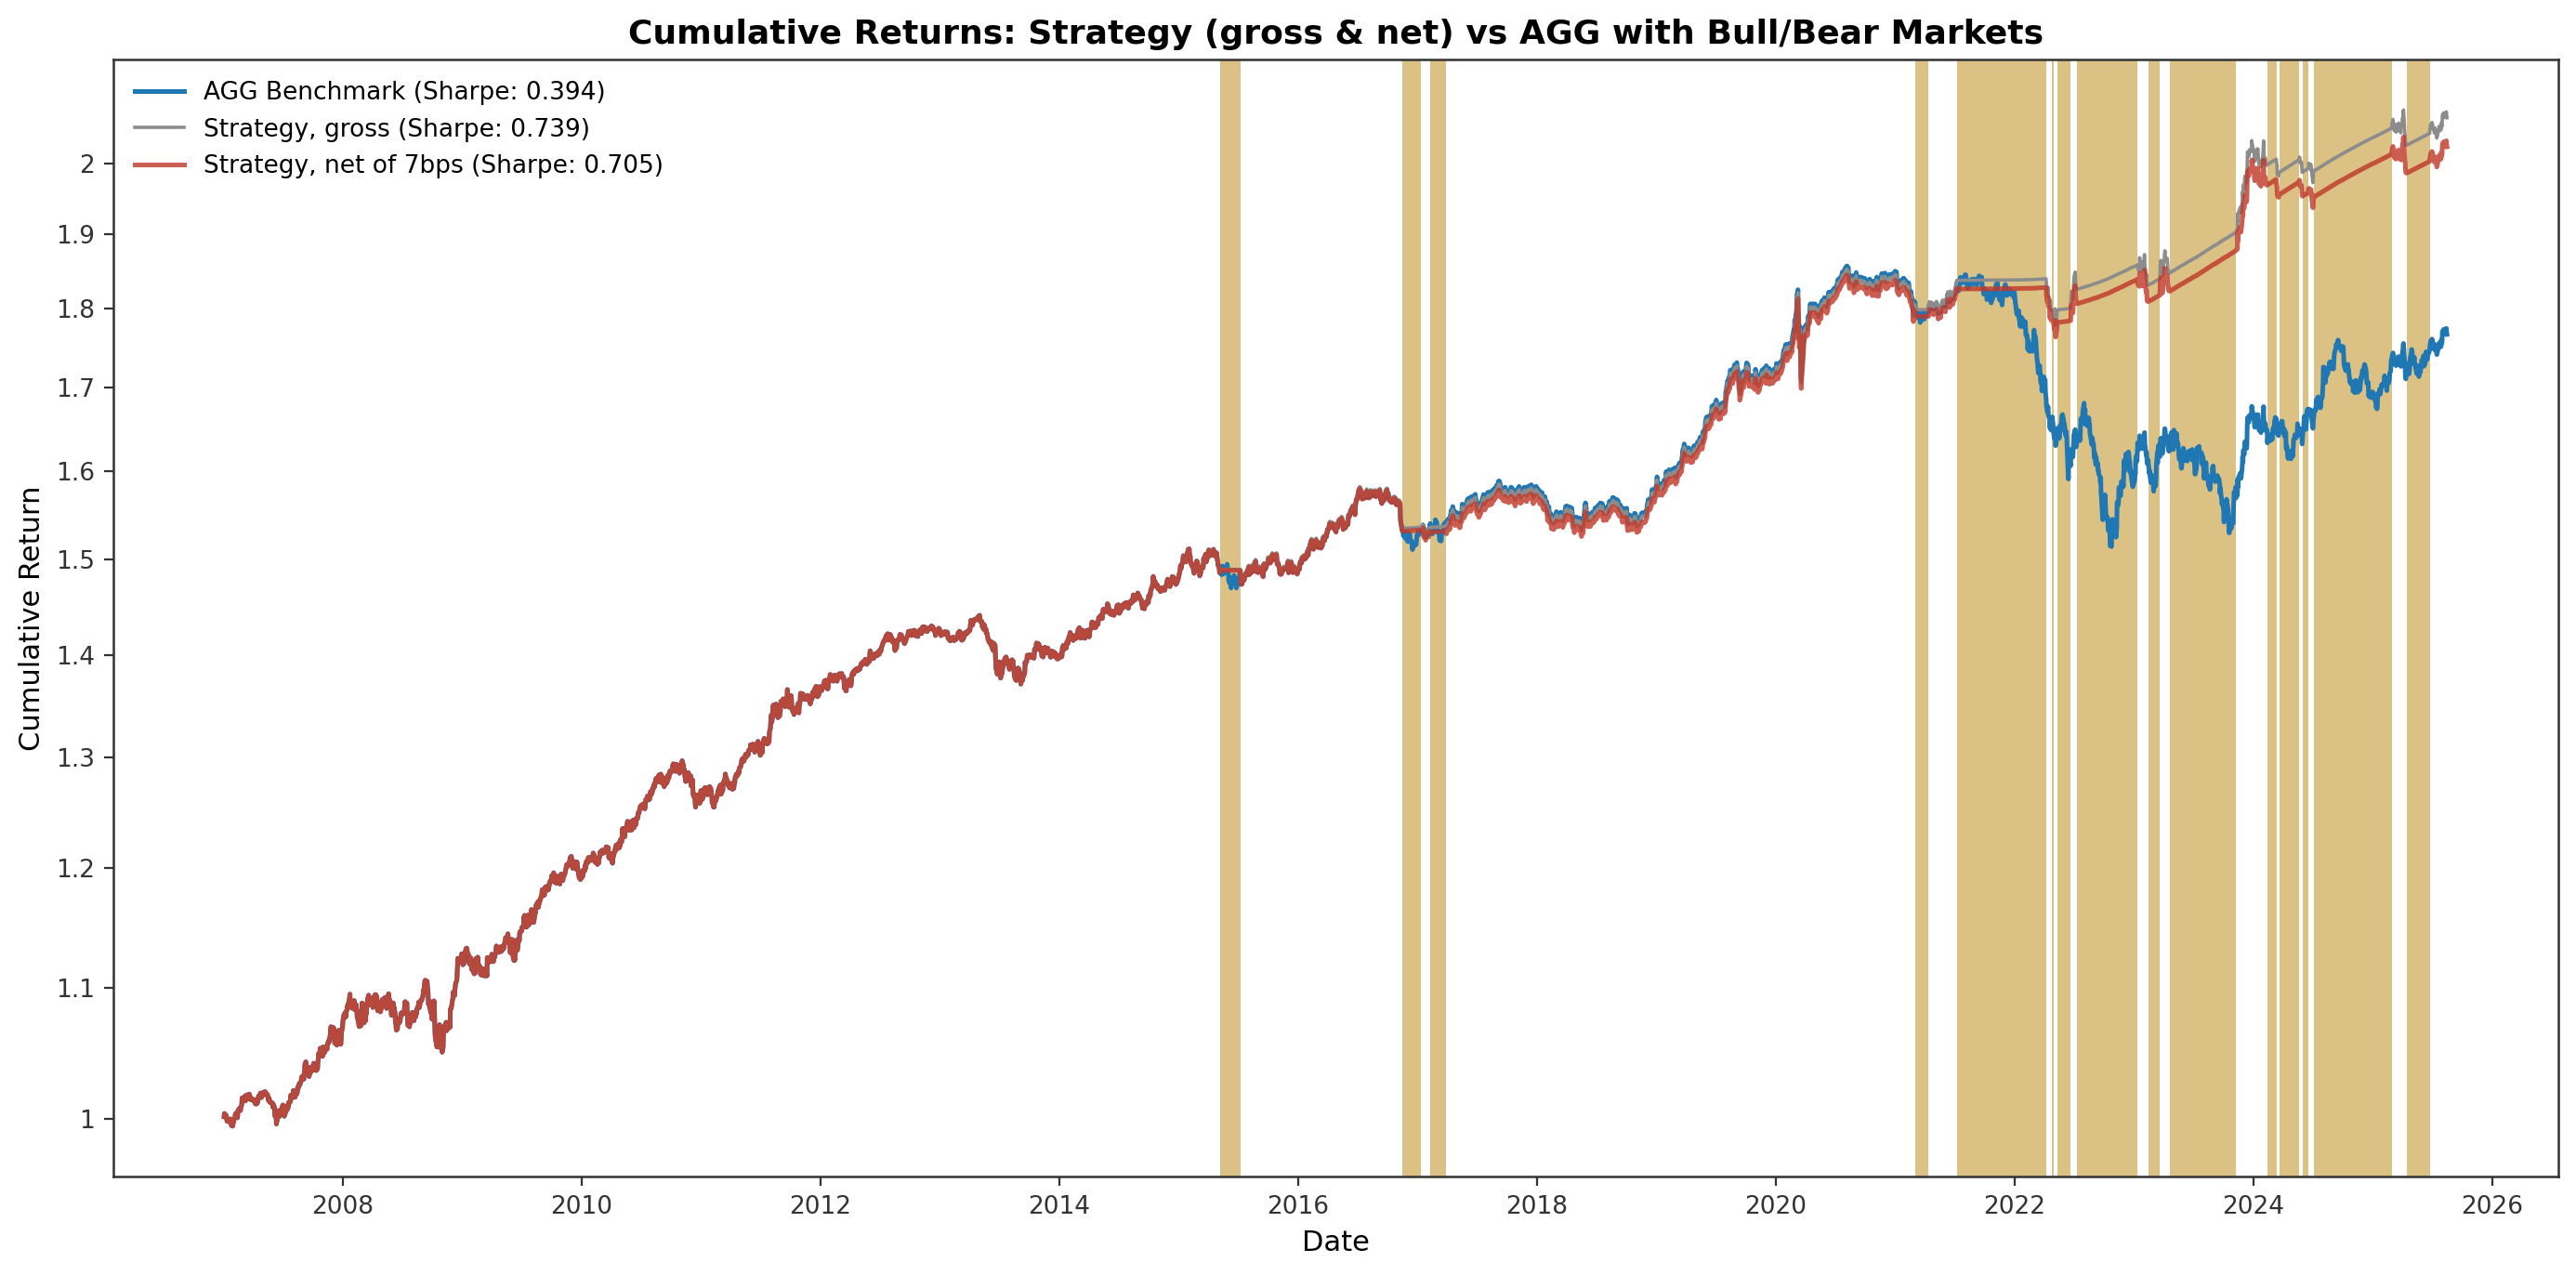

In [9]:
df_test = df_view.copy()
df_test["DateTime"] = pd.to_datetime(df_test["DateTime"])

df_test[f"{ASSET}_Return"] = df_test[f"{ASSET}"].pct_change()

df_test["rf_daily"] = (1 + df_test["DGS3MO"] / 100) ** (1 / 252) - 1

COST_BPS = 7
trade_flag = (df_test["Position"] != df_test["Position"].shift(1)) & df_test["Position"].notna() & df_test["Position"].shift(1).notna()
df_test["Strategy_Return_gross_cash0"] = df_test["Position"] * df_test[f"{ASSET}_Return"]
df_test["Strategy_Return_cash0"] = df_test["Strategy_Return_gross_cash0"] - trade_flag.astype(float) * (COST_BPS / 10000)
df_test["Strategy_Return_gross"] = df_test["Strategy_Return_gross_cash0"] + (1 - df_test["Position"]) * df_test["rf_daily"]
df_test["Strategy_Return"] = df_test["Strategy_Return_gross"] - trade_flag.astype(float) * (COST_BPS / 10000)

df_test[f"{ASSET}_Cumulative"] = (1 + df_test[f"{ASSET}_Return"]).cumprod()
df_test["Strategy_Cumulative"] = (1 + df_test["Strategy_Return"]).cumprod()
df_test["Strategy_Cumulative_gross"] = (1 + df_test["Strategy_Return_gross"]).cumprod()
df_test["Strategy_Cumulative_cash0"] = (1 + df_test["Strategy_Return_cash0"]).cumprod()
df_test["Strategy_Cumulative_gross_cash0"] = (1 + df_test["Strategy_Return_gross_cash0"]).cumprod()

def sharpe_ratio(returns, rf_daily=None):
    returns = pd.Series(returns).dropna()
    ann_return = (1 + returns.mean()) ** 252 - 1
    ann_std = returns.std(ddof=1) * np.sqrt(252)
    if rf_daily is not None:
        rf_daily = pd.Series(rf_daily).reindex(returns.index).ffill()
        ann_rf = (1 + rf_daily.mean()) ** 252 - 1
    else:
        ann_rf = 0
    return (ann_return - ann_rf) / ann_std if ann_std != 0 else np.nan

strategy_sharpe = sharpe_ratio(df_test["Strategy_Return"], df_test["rf_daily"])
strategy_sharpe_gross = sharpe_ratio(df_test["Strategy_Return_gross"], df_test["rf_daily"])
asset_sharpe = sharpe_ratio(df_test[f"{ASSET}_Return"], df_test["rf_daily"])

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(df_test["DateTime"].values, df_test[f"{ASSET}_Cumulative"].values, label=f"{ASSET_DISPLAY} Benchmark (Sharpe: {asset_sharpe:.3f})", color=PALETTE['benchmark'], linewidth=1.8)
ax.plot(df_test["DateTime"].values, df_test["Strategy_Cumulative_gross"].values, label=f"Strategy, gross (Sharpe: {strategy_sharpe_gross:.3f})", color=PALETTE['gross'], linewidth=1.3)
ax.plot(df_test["DateTime"].values, df_test["Strategy_Cumulative"].values, label=f"Strategy, net of {COST_BPS}bps (Sharpe: {strategy_sharpe:.3f})", color=PALETTE['strategy'], alpha=STRATEGY_LINE_ALPHA, linewidth=1.8)

shade_regime(ax, df_test["DateTime"], df_test["Position"])

ax.set_title(f"Cumulative Returns: Strategy (gross & net) vs {ASSET_DISPLAY} with Bull/Bear Markets")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return")
log_wealth_axis(ax)
ax.legend(loc='upper left')
plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
plt.savefig(FIG_DIR + FIG_NAME, dpi=200, bbox_inches='tight')
plt.show()


## Performance metrics (benchmark vs. 0/1 regime strategy)

In [10]:
from scipy.stats import skew

def sortino_ratio(returns):
    returns = pd.Series(returns).dropna()
    downside_std = returns[returns < 0].std(ddof=1)
    return returns.mean() / downside_std * np.sqrt(252) if downside_std != 0 and pd.notna(downside_std) else np.nan

def max_drawdown(cumulative_returns):
    cumulative_returns = pd.Series(cumulative_returns)
    return (cumulative_returns / cumulative_returns.cummax() - 1).min()

def skewness(returns):
    return skew(pd.Series(returns).dropna(), nan_policy='omit')

def annualized_return(returns):
    _r = pd.Series(returns).dropna()
    return (1 + _r).prod() ** (252 / len(_r)) - 1 if len(_r) else np.nan

def annualized_vol(returns):
    return pd.Series(returns).dropna().std(ddof=1) * np.sqrt(252)

def information_coefficient(predictions, actual_returns):
    return np.corrcoef(predictions, actual_returns)[0, 1] if len(predictions) > 1 else np.nan

METRIC_NAMES = ["Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio", "Max Drawdown", "Skewness", "IC (Pearson)"]

d = df_test[[f"{ASSET}_Return", f"{ASSET}_Cumulative", 'rf_daily', 'Position',
             'Strategy_Return', 'Strategy_Return_gross', 'Strategy_Cumulative', 'Strategy_Cumulative_gross',
             'Strategy_Return_cash0', 'Strategy_Return_gross_cash0', 'Strategy_Cumulative_cash0', 'Strategy_Cumulative_gross_cash0']].dropna()

def metric_column(ret, cum, with_ic=True):
    return [annualized_return(ret), annualized_vol(ret), sharpe_ratio(ret, d['rf_daily']),
            sortino_ratio(ret), max_drawdown(cum), skewness(ret),
            information_coefficient(d['Position'], d[f"{ASSET}_Return"]) if with_ic else np.nan]

metrics_df = pd.DataFrame({
    "Metric": METRIC_NAMES,
    f"{ASSET_DISPLAY} benchmark": metric_column(d[f"{ASSET}_Return"], d[f"{ASSET}_Cumulative"], with_ic=False),
    "w/ Regime (gross)": metric_column(d["Strategy_Return_gross"], d["Strategy_Cumulative_gross"]),
    f"w/ Regime (net of {COST_BPS}bps)": metric_column(d["Strategy_Return"], d["Strategy_Cumulative"]),
}).set_index("Metric")
metrics_df.round(6)

,AGG benchmark,w/ Regime (gross),w/ Regime (net of 7bps)
Metric,,,
Annual Return,0.031094,0.039845,0.038671
Annual Volatility,0.044174,0.034911,0.034913
Sharpe Ratio,0.394228,0.738828,0.705145
Sortino Ratio,1.011805,1.433856,1.393434
Max Drawdown,-0.184050,-0.062984,-0.062984
Skewness,-0.154037,-0.290347,-0.297984
IC (Pearson),NaN,0.029891,0.029891


## Turnover

In [11]:
trades = (df_test['Position'] != df_test['Position'].shift(1)) & df_test['Position'].notna() & df_test['Position'].shift(1).notna()
n_trades = int(trades.sum())
n_days = int(df_test['Position'].notna().sum())

turnover_df = pd.DataFrame({
    "Number of trades": [n_trades],
    "Trading days": [n_days],
    "Trades per year": [round(n_trades / (n_days / 252), 1)],
    "Average holding period (days)": [round(n_days / n_trades, 1)],
    "Cost per trade (bps)": [COST_BPS],
})
turnover_df

,Number of trades,Trading days,Trades per year,Average holding period (days),Cost per trade (bps)
0,30,4683,1.6,156.1,7


## Holding-period extension: lookback confirmation

In [12]:
df_lb = df_view[['DateTime', ASSET, 'Regime_Forecast', 'DGS3MO', 'Position_raw']].copy()
df_lb['DateTime'] = pd.to_datetime(df_lb['DateTime'])
df_lb = df_lb.sort_values('DateTime').reset_index(drop=True)
df_lb[f'{ASSET}_Return'] = df_lb[ASSET].pct_change()
df_lb['rf_daily'] = (1 + df_lb['DGS3MO'] / 100) ** (1 / 252) - 1
df_lb = df_lb.dropna(subset=[f'{ASSET}_Return']).reset_index(drop=True)

LOOKBACK_THRESH = 0.8
lookback_list = [1, 10, 20, 30]

def lookback_name(lb):
    return 'Main' if lb == 1 else f'N={lb}'

def confirm_position(pos_lagged, lb, thr=LOOKBACK_THRESH):
    main = hold_until_n(pos_lagged, SMOOTH_N)
    if lb == 1:
        return main
    share = main.rolling(lb).mean()
    return (share >= thr - 1e-12).astype(float).where(share.notna())

def round_half_up(x):
    return int(np.floor(x + 0.5))

lookback_summary_rows = []
for lb in lookback_list:
    pos = confirm_position(df_lb['Position_raw'], lb)
    ret_gross = pos * df_lb[f'{ASSET}_Return'] + (1 - pos) * df_lb['rf_daily']
    trades_lb = (pos != pos.shift(1)) & pos.notna() & pos.shift(1).notna()
    n_trades = int(trades_lb.sum())
    n_days = int(pos.notna().sum())

    posn = pos.dropna().reset_index(drop=True)
    spells = posn.groupby((posn != posn.shift()).cumsum()).size()

    ret = ret_gross - trades_lb.astype(float) * (COST_BPS / 10000)
    cum = (1 + ret.fillna(0)).cumprod()

    lookback_summary_rows.append({
        'Lookback': lookback_name(lb),
        'Trades': n_trades,
        'Trades/Yr': round(n_trades / (n_days / 252), 2),
        'IC': pos.corr(df_lb[f'{ASSET}_Return']),
        'AnnRet': annualized_return(ret),
        'Sharpe': sharpe_ratio(ret, df_lb['rf_daily']),
        'Sortino': sortino_ratio(ret),
        'MaxDD': max_drawdown(cum),
        'Holding P25 (d)': round_half_up(spells.quantile(.25)),
        'Holding Median (d)': round_half_up(spells.median()),
        'Holding P75 (d)': round_half_up(spells.quantile(.75)),
    })

lookback_summary_df = pd.DataFrame(lookback_summary_rows).set_index('Lookback')
lookback_summary_df.round(6)

,Trades,Trades/Yr,IC,AnnRet,Sharpe,Sortino,MaxDD,Holding P25 (d),Holding Median (d),Holding P75 (d)
Lookback,,,,,,,,,,
Main,30,1.61,0.029891,0.038671,0.705145,1.393434,-0.062984,15,31,64
N=10,26,1.40,0.033160,0.040168,0.767704,1.457456,-0.062984,16,41,115
N=20,18,0.97,0.028418,0.039468,0.761347,1.438808,-0.062984,31,51,218
N=30,12,0.65,0.029157,0.039954,0.788496,1.451804,-0.062984,45,68,322


## Sensitivity to the cash assumption: cash = T-bill (main) vs. cash = 0

In [13]:
metrics_cash0_df = pd.DataFrame({
    "Metric": METRIC_NAMES[:6],
    "Cash = T-bill": metric_column(d["Strategy_Return"], d["Strategy_Cumulative"])[:6],
    "Cash = 0": metric_column(d["Strategy_Return_cash0"], d["Strategy_Cumulative_cash0"])[:6],
}).set_index("Metric")
metrics_cash0_df.round(6)

,Cash = T-bill,Cash = 0
Metric,,
Annual Return,0.038671,0.032359
Annual Volatility,0.034913,0.034923
Sharpe Ratio,0.705145,0.524094
Sortino Ratio,1.393434,1.173546
Max Drawdown,-0.062984,-0.062984
Skewness,-0.297984,-0.264829


In [14]:
rows = []
for lb in lookback_list:
    pos = confirm_position(df_lb['Position_raw'], lb)
    trades_lb = (pos != pos.shift(1)) & pos.notna() & pos.shift(1).notna()
    ret0 = pos * df_lb[f'{ASSET}_Return'] - trades_lb.astype(float) * (COST_BPS / 10000)
    cum0 = (1 + ret0.fillna(0)).cumprod()
    name = lookback_name(lb)
    rows.append({
        'Lookback': name,
        'Sharpe (cash = T-bill)': lookback_summary_df.loc[name, 'Sharpe'], 'Sharpe (cash = 0)': sharpe_ratio(ret0, df_lb['rf_daily']),
        'AnnRet (cash = T-bill)': lookback_summary_df.loc[name, 'AnnRet'], 'AnnRet (cash = 0)': annualized_return(ret0),
    })
pd.DataFrame(rows).set_index('Lookback').round(6)

,Sharpe (cash = T-bill),Sharpe (cash = 0),AnnRet (cash = T-bill),AnnRet (cash = 0)
Lookback,,,,
Main,0.705145,0.524094,0.038671,0.032359
N=10,0.767704,0.565744,0.040168,0.033298
N=20,0.761347,0.541157,0.039468,0.032100
N=30,0.788496,0.551697,0.039954,0.032139


## 2022 rate-hike selloff: benchmark vs. regime strategy

In [15]:
start = df_test.loc[df_test['DateTime'] < '2022-01-01'].index[-1]
low = df_test.loc[df_test['DateTime'].dt.year == 2022, f"{ASSET}_Cumulative"].idxmin()
episode_df = pd.DataFrame({
    "From (2021 year-end)": [df_test.loc[start, 'DateTime'].date()],
    "To (2022 low)": [df_test.loc[low, 'DateTime'].date()],
    f"{ASSET_DISPLAY} benchmark": [df_test.loc[low, f"{ASSET}_Cumulative"] / df_test.loc[start, f"{ASSET}_Cumulative"] - 1],
    f"w/ Regime (net of {COST_BPS}bps)": [df_test.loc[low, "Strategy_Cumulative"] / df_test.loc[start, "Strategy_Cumulative"] - 1],
}).round(6)
episode_df

,From (2021 year-end),To (2022 low),AGG benchmark,w/ Regime (net of 7bps)
0,2021-12-31,2022-10-24,-0.168228,-0.002278
